# Introduction to Model Context Protocol (MCP)

A practical guide to understanding MCP — the open standard that connects AI applications to external tools and data sources. This notebook covers the core concepts, architecture, advantages, and real-world usage patterns of MCP across three modules.

## Table of Contents

- [Module 01: Understanding the Model Context Protocol](#module-01)
- [Module 02: Advantages of MCP](#module-02)
- [Module 03: MCP in Action](#module-03)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

<a id="module-01"></a>
## Module 01: Understanding the Model Context Protocol

This module introduces MCP from first principles — what it is, who participates, and what building blocks it provides.

### What Is the Model Context Protocol?

Before defining MCP, it helps to understand two foundational terms:

**Standard** — A shared agreement on how something should work. One way everyone follows, so things stay compatible.

**Protocol** — A set of rules for communication. It defines the format, order, and meaning of messages exchanged.

**Open / Open-source** — Publicly available for anyone to use or build on.

> **Model Context Protocol (MCP):** An open-source standard protocol for connecting AI applications to external tools and data.

### MCP Participants: Hosts, Clients, and Servers

MCP defines three roles that work together to connect an AI application to external context.


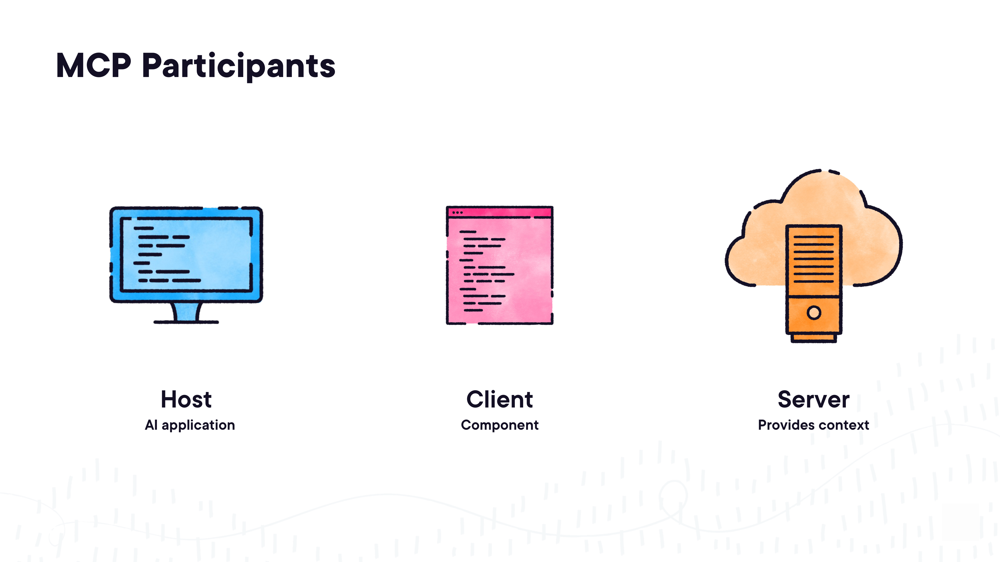

In [2]:
render_diagram(Path("assets/01-mcp-participants-overview.png"))

| Role | Description |
|---|---|
| **Host** | The AI application (e.g. VS Code, Claude Desktop). The host instantiates one or more clients. |
| **Client** | A component inside the host that manages the connection to a single MCP server. |
| **Server** | An external program that provides context — tools, resources, and prompts — to the AI. |

The **host** is the application the user interacts with. It instantiates **clients** internally, and each client connects to one **server** that provides context. Multiple servers can be connected simultaneously, each adding different capabilities.

#### Concrete example

Visual Studio Code (host) connects via MCP client objects to the Angular CLI MCP server, which searches documentation and exposes tools.


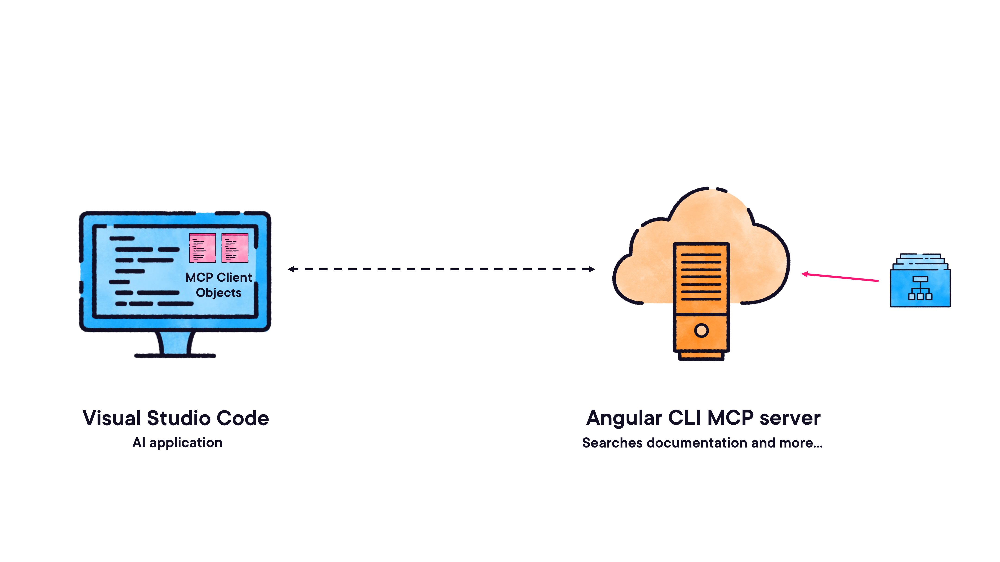

In [3]:
render_diagram(Path("assets/02-angular-cli-mcp-example.png"))

### MCP Primitives: Tools, Resources, and Prompts

**Primitive** — The smallest building block of a system. In MCP, primitives are the types of context a server can provide.

MCP defines exactly three primitives:

| Primitive | Purpose | Examples |
|---|---|---|
| **Tool** | Executable functions the AI can invoke to perform actions | Query a database, call an API, run a calculation |
| **Resource** | Read-only contextual information the AI can request | Files, database schemas, documentation |
| **Prompt** | Reusable templates a user can select to guide AI responses | Calendar prompt templates, structured query starters |

Together these primitives cover the full surface area of what an AI needs from external systems: actions to perform, data to read, and templates to guide interaction.


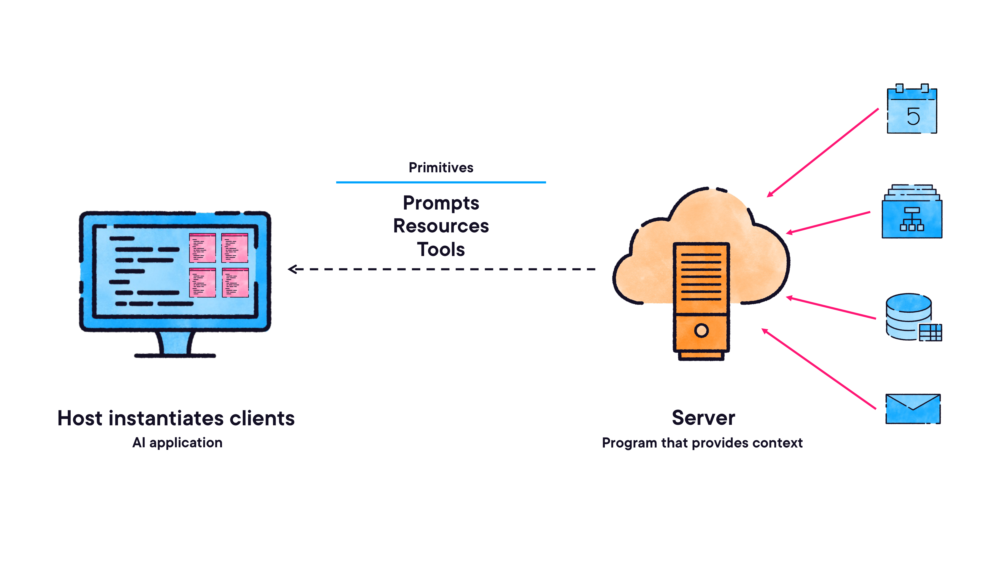

In [4]:
render_diagram(Path("assets/03-mcp-primitives-all-three.png"))

### How Data is Transferred

MCP uses a two-layer model for data transfer.

#### Data Layer: JSON-RPC

All messages between host/clients and server use **JSON-RPC 2.0** — a lightweight remote procedure call protocol that encodes requests and responses as JSON objects.

Example request to list available tools:


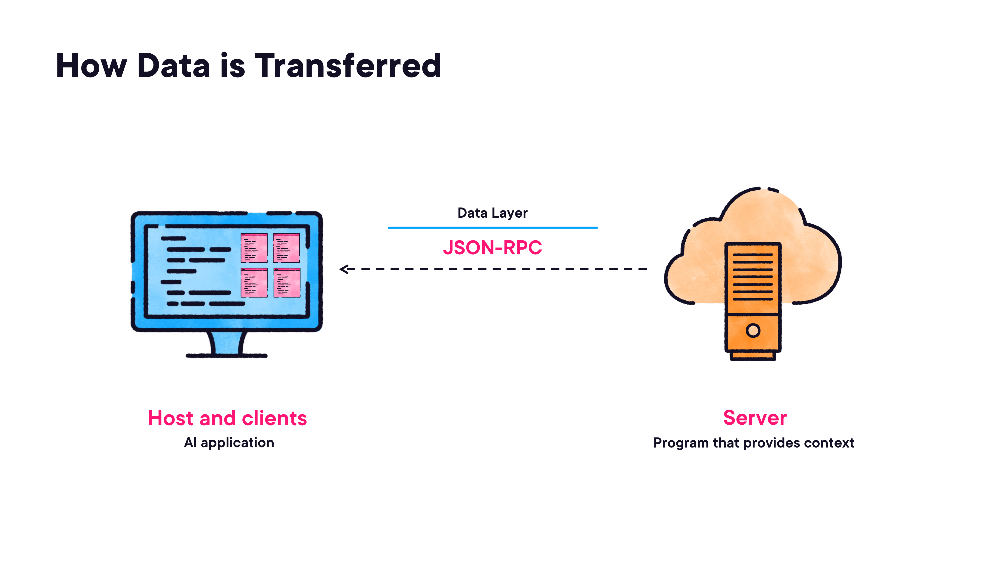

In [5]:
render_diagram(Path("assets/04-mcp-json-rpc-data-layer.png"))


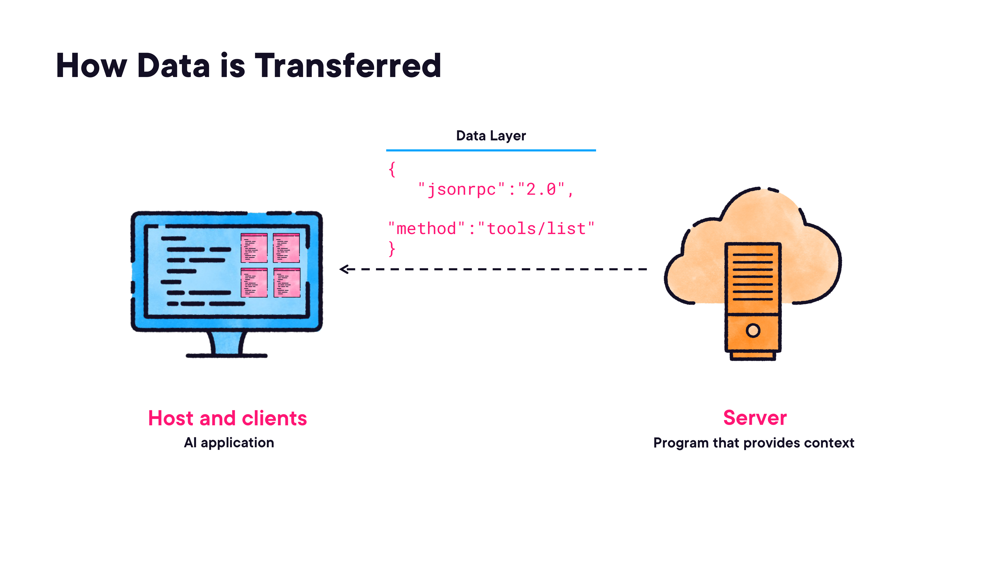

In [6]:
render_diagram(Path("assets/05-mcp-json-payload-example.png"))

#### Transport Layer: STDIO or HTTP

JSON-RPC messages are carried over one of two transport mechanisms:

- **Local (STDIO)** — Standard input/output; used when the MCP server runs as a local subprocess on the same machine as the host.
- **Remote (HTTP)** — HTTP with Server-Sent Events (SSE); used when the MCP server is hosted remotely and accessed over a network.

The choice of transport is an operational concern — the protocol and message format are identical in both cases.

<a id="module-02"></a>
## Module 02: Advantages of MCP

This module examines why MCP was created, what problems it solves over existing integration approaches, and the specific benefits it provides.

### The Integration Problem: Existing Alternatives

**Integration** — Connecting an application to something outside itself: a tool it can use, data it can read, a service it can interact with.

Before MCP, connecting AI applications to external tools meant choosing between several approaches, each with significant limitations:

| Approach | Limitation |
|---|---|
| Model-specific plugins | Not portable — only works with one AI model |
| Manual API integrations | Don't scale — each integration is custom-built |
| Language-specific frameworks | Tied to runtime — locks you into a particular language or environment |

> Inflexible solutions result in frustration.

The core problem: the more integration paths you need, the more complicated your code becomes. Every new data source or tool requires a new bespoke connection.

### Why MCP: Benefits over Alternatives

> We need one standard that can connect any AI application to any tool or data source.

MCP addresses this by providing a single open protocol that any client and any server can implement. Once a server exposes its capabilities via MCP, it is immediately usable by every MCP-compatible host.


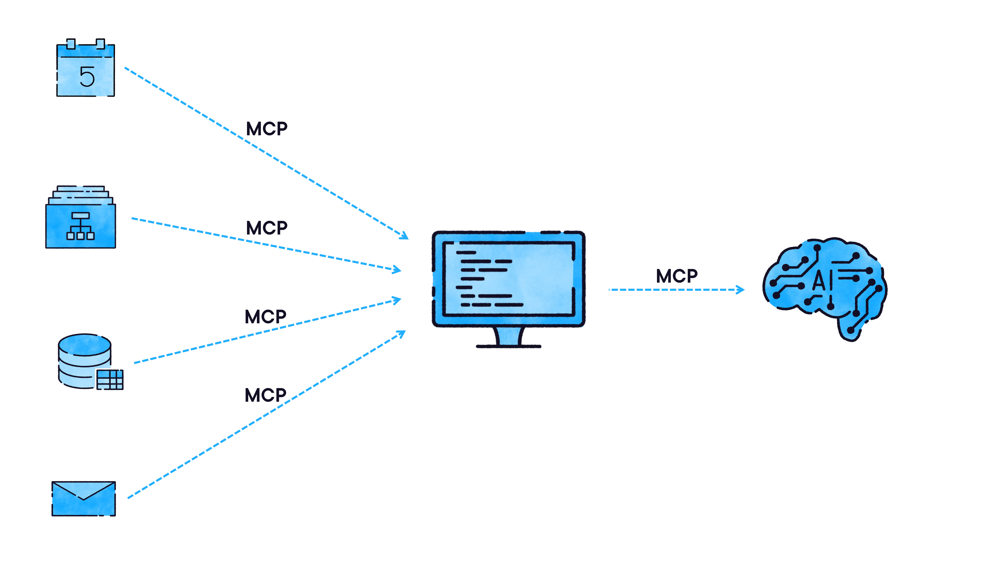

In [7]:
render_diagram(Path("assets/06-mcp-build-once-use-everywhere.png"))

**Build once. Use everywhere.** — A single MCP server (calendar, file system, database, messaging) connects to any MCP-compatible host via the same protocol, flowing context to the AI model.

#### The Five Benefits of MCP

- **Open protocol** — Language-agnostic; any runtime can implement it
- **Pre-built integrations** — A growing ecosystem of ready-made MCP servers for common services (GitHub, Postgres, Slack, Google Drive, file system, and more)
- **Standardized structure** — Tools, resources, and prompts are defined consistently across all servers
- **Client flexibility** — The same server works with IDEs, chat interfaces, CLI tools, and custom applications
- **Reduced hallucinations** — MCP connects models to real, current data rather than relying on training knowledge

#### MCP vs. Alternatives: Summary

| Approach | Limitation | MCP Advantage |
|---|---|---|
| Model-specific plugins | Not portable | Open protocol — works with any model |
| Manual API integrations | Don't scale | Pre-built and standardized |
| Language-specific frameworks | Tied to runtime | Language-agnostic |

#### Reduced Hallucinations: How MCP Helps

LLMs are trained on a fixed dataset — they are not trained on your data, and without live context they fill gaps with educated guesses that can be confidently wrong.

MCP addresses this by providing a channel to inject current, grounded information into the model's context window:

- Models aren't trained on your data → MCP connects models to real data
- Without context, LLMs fill in gaps → Current files and live information are provided
- Guesses can be confidently wrong → Grounded answers guide the model's pattern matching

> One protocol. Any client. Any server.

<a id="module-03"></a>
## Module 03: MCP in Action

This module covers real-world use cases, the MCP ecosystem, the request-response lifecycle, and how context flows through an active MCP session.

### Use Cases and the MCP Ecosystem

#### Common Use Cases

| Use Case | Type | What MCP enables |
|---|---|---|
| **Chatbots** | Conversational interfaces | Answer questions using real data, look up information on demand, take actions on behalf of users |
| **IDE assistants** | Developer tools | Read data outside the project context, access documentation, run commands and tools |
| **Agents** | Autonomous task runners | Access tools and data mid-task, choose from available services, gather context as the task is carried out |

#### Example Hosts and Clients

Real MCP-compatible host applications: Claude Desktop, VS Code extensions, Cursor, Amazon Q, CLI tools, custom apps.

#### Example Servers

Ready-made MCP servers exist for: Google Drive, Postgres, GitHub, Slack, File system, and many more.

> The ecosystem grows because the standard is open.

Any developer can publish an MCP server — because the protocol is open, every new server immediately works with every existing MCP host.

### The MCP Request-Response Flow

Every MCP session follows a structured lifecycle with three phases:

| Phase | Purpose |
|---|---|
| **Initialization** | Establish connection and negotiate capabilities |
| **Operation** | Exchange messages and call tools |
| **Shutdown** | Cleanly close the connection |

This makes MCP interactions **structured**, **predictable**, and **standardized**.

#### Phase 1: Initialization

The host sends an `initialize` request carrying the **protocol version** and **client capabilities**. The server responds with its own capabilities and server info. This negotiation ensures both sides agree on what features are available before any work begins.

#### Capability Negotiation

During initialization, each side declares what it supports:

| Party | Capability |
|---|---|
| Client | Roots |
| Client | Sampling |
| Server | Prompts |
| Server | Resources |
| Server | Tools |

**Roots** allows the client to expose filesystem roots to the server. **Sampling** allows the server to request completions from the LLM through the client.

#### Phase 2: Operation

During the operation phase the host calls `tools/list` to discover available tools, then invokes them on behalf of the user. Here is a full example of a user query flowing through the system:


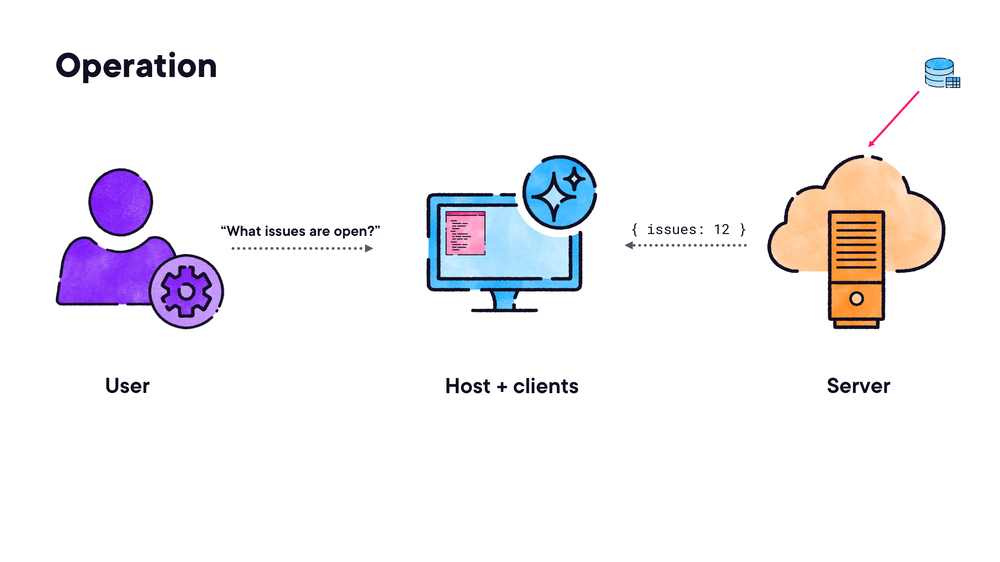

In [8]:
render_diagram(Path("assets/07-mcp-operation-request-response.png"))

**Flow:** User asks "What issues are open?" → Host+clients call `get_issues` tool on the server → Server queries its data source and returns `{ issues: 12 }` → Host uses that data to answer "The open issues are…"

The user can then continue the conversation — "What's the oldest?", "Assign it to me" — and the host calls further tools as needed. Each turn adds to the conversation context.

#### Phase 3: Shutdown

When the session ends, the connection is cleanly closed. MCP defines explicit shutdown behaviour to ensure no messages are lost and resources are freed properly.

### The Lifecycle of Context

> An LLM's output is only as good as its context.

MCP's three primitives each contribute a different type of context to the model:

| Primitive | Context type |
|---|---|
| Tools | Actions available to perform |
| Resources | Data available to read |
| Prompts | Templates available to reuse |

During **initialization**, the server delivers tool definitions, resource lists, and prompt templates to the host — this is what populates the model's awareness of what it can do. During **operation**, actual tool results and resource content flow back as real data.

> MCP provides context. The LLM uses it.

#### Context Balance

Managing context requires balance. Too much context degrades output quality — LLMs have finite context windows, and flooding them with irrelevant data dilutes the signal. A well-designed MCP server exposes only what is relevant to the task at hand.

---

### Summary

| Concept | Key point |
|---|---|
| MCP | An open-source standard protocol connecting AI applications to external tools and data |
| Host | The AI application; instantiates clients |
| Client | Component inside the host; manages one server connection |
| Server | Provides context via tools, resources, and prompts |
| Tool | Executable function on the server — performs actions |
| Resource | Read-only data the AI can request |
| Prompt | Reusable template the user can select |
| JSON-RPC 2.0 | The data format for all MCP messages |
| Transport | STDIO (local) or HTTP (remote) |
| Lifecycle phases | Initialization → Operation → Shutdown |
| Context balance | More context is not always better — relevance matters |